# Chapter 3 · Lebesgue measure and measurable functions: interactive demos

Companion to Chapter 3 of the notes [*Probability with Measure Theory*](https://gennaroalberto.github.io/probability-measure-theory/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/probability-measure-theory/blob/main/code/notebooks/03-measurable-functions.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/probability-measure-theory#subdirectory=code"

import math
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from probnotes.measurable import (cantor_function, cantor_stage, cantor_stage_measure,
                                  cantor_limit_measure, dyadic_approximation, dyadic_levels,
                                  is_measurable, monte_carlo_measure, power_set, preimage,
                                  sigma_of_function, atoms)
from probnotes.style import COBALT, GOLD, GREY, INK, use_style

GREEN = "#1BAF7A"
use_style()

## 1. Simple functions approaching $f$

The approximation theorem (Theorem 3.40 in the notes) builds, for a measurable $f\ge0$,

$$f_n(x)=\begin{cases}\frac{i-1}{2^n} & \text{if } \frac{i-1}{2^n}\le f(x)<\frac{i}{2^n},\ i=1,\dots,n2^n,\\ n & \text{if } f(x)\ge n,\end{cases}
\qquad\text{that is,}\qquad f_n=\min\big(n,\,2^{-n}\lfloor 2^n f\rfloor\big).$$

Each $f_n$ takes at most $n2^n+1$ values, $f_n\le f_{n+1}\le f$, and $f_n\to f$ pointwise. Where $f<n$
the error is below $2^{-n}$; where $f\ge n$ the function is cut at height $n$. On the right, the largest
and the mean error over the plotted range, for every $n$ up to 12; the current $n$ is marked.

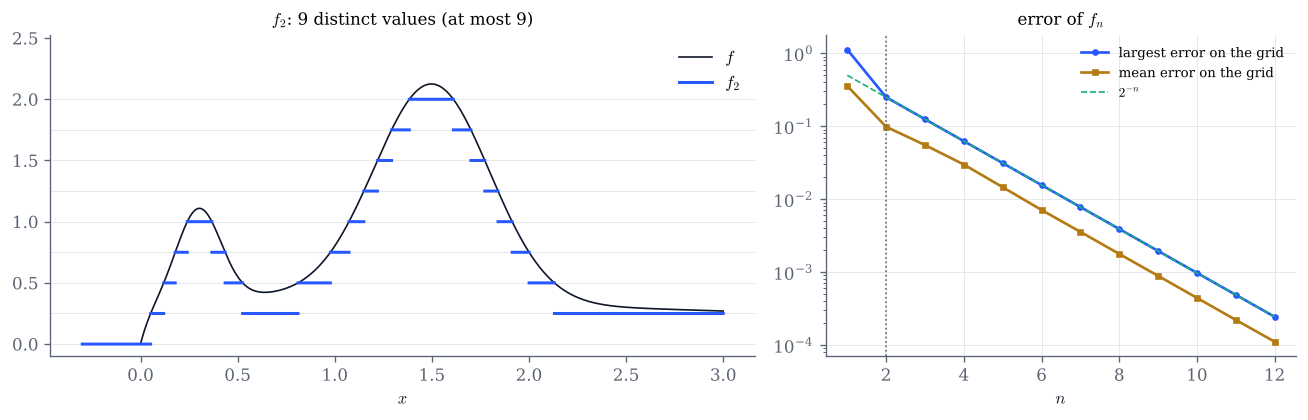

In [2]:
FUNCTIONS = {
    "bump (as in the notes)": (lambda x: np.where(x > 0, (0.42 + 0.72 * np.exp(-((x - 0.3) / 0.16) ** 2)
                                + 1.78 * np.exp(-((x - 1.5) / 0.42) ** 2) - 0.05 * x)
                                * (1 - np.exp(-14 * np.clip(x, 0, None))), 0.0), (-0.3, 3.0)),
    "12 x (1 - x) on [0, 1]": (lambda x: 12 * x * (1 - x), (0.0, 1.0)),
    "-log x on (0, 1) (unbounded)": (lambda x: -np.log(x), (1e-9, 1.0)),
    "with a jump: x^2 + 1_(x > 1/2)": (lambda x: x**2 + (x > 0.5), (0.0, 1.0)),
}


def broken(x, y):
    # NaNs at the jumps of a step function, so that no vertical segments are drawn
    jumps = np.flatnonzero(np.diff(y) != 0) + 1
    return np.insert(x, jumps, np.nan), np.insert(y.astype(float), jumps, np.nan)


def dyadic_demo(n=2, function="bump (as in the notes)"):
    f, (a, b) = FUNCTIONS[function]
    x = np.linspace(a, b, 20001)
    fx = f(x)
    fn = dyadic_approximation(fx, n)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.5, 1]})
    top = min(fx.max(), 6.0)
    for level in dyadic_levels(n):
        if level <= top + 0.5 and len(dyadic_levels(n)) <= 400:
            ax.axhline(level, color=GREY, lw=0.3, alpha=0.3, zorder=0)
    ax.plot(x, fx, color=INK, lw=1.0, label="$f$")
    xs, ys = broken(x, fn)
    ax.plot(xs, ys, color=COBALT, lw=1.8, label=f"$f_{{{n}}}$")
    ax.set(xlabel="$x$", ylim=(-0.1, top + 0.4),
           title=f"$f_{{{n}}}$: {len(np.unique(fn))} distinct values (at most {n * 2**n + 1})")
    ax.grid(False)
    ax.legend(loc="upper right")
    ns = np.arange(1, 13)
    sup_err = [np.max(fx - dyadic_approximation(fx, k)) for k in ns]
    mean_err = [np.mean(fx - dyadic_approximation(fx, k)) for k in ns]
    ax2.plot(ns, sup_err, color=COBALT, marker="o", ms=3, label="largest error on the grid")
    ax2.plot(ns, mean_err, color=GOLD, marker="s", ms=3, label="mean error on the grid")
    ax2.plot(ns, 2.0 ** -ns, color=GREEN, ls="--", lw=1, label="$2^{-n}$")
    ax2.axvline(n, color=GREY, ls=":", lw=1)
    ax2.set(yscale="log", xlabel="$n$", title="error of $f_n$")
    ax2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

dyadic_demo()

In [3]:
# Explore: move n and change the function. For the unbounded -log x the largest error never
# goes down (it is the cut at height n), while the mean error still halves at each step.
interact(dyadic_demo,
         n=IntSlider(value=2, min=1, max=10, continuous_update=False, description="n"),
         function=Dropdown(options=list(FUNCTIONS), value="bump (as in the notes)", description="f"));

## 2. The Cantor set, thin and fat

Stage $k$ removes, from the middle of each of the $2^{k-1}$ intervals left, an open interval of length $r^k$.
For $r=1/3$ these are the stages $C_k$ of the Cantor set, with $m(C_k)=(2/3)^k\to0$: the Cantor set is
negligible (Remark 3.5). For $r<1/3$ the limit set is a *fat* Cantor set, of measure $(1-3r)/(1-2r)>0$, which
still contains no interval. On the right, the Cantor function maps the Cantor set onto $[0,1]$: that is why
the Cantor set is uncountable.

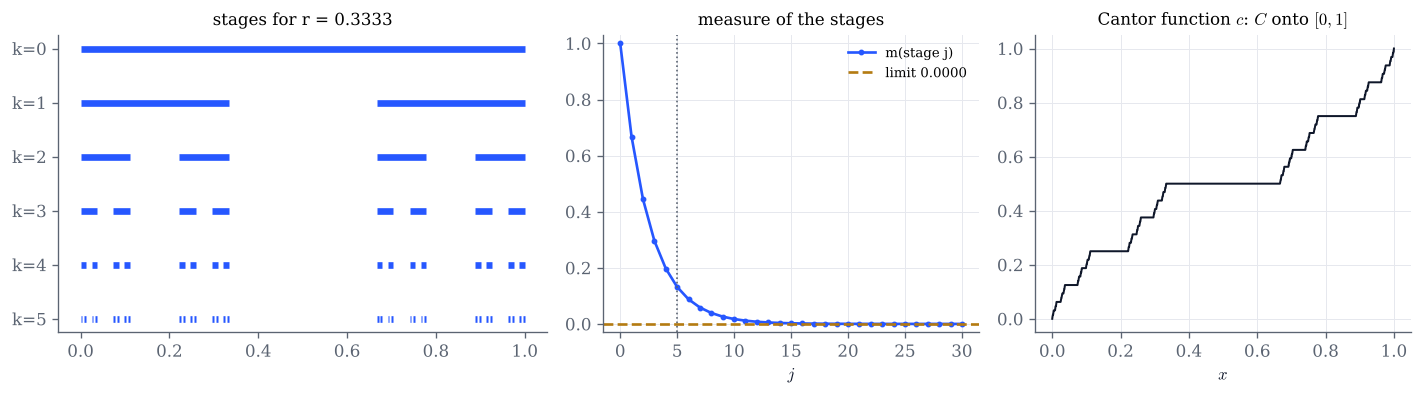

In [4]:
def cantor_demo(k=5, r=1/3):
    fig, (ax, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1.3, 1, 1]})
    for j in range(k + 1):
        I = cantor_stage(j, r)
        ax.hlines(np.full(len(I), -j), I[:, 0], I[:, 1], color=COBALT, lw=4)
    ax.set(yticks=-np.arange(k + 1), yticklabels=[f"k={j}" for j in range(k + 1)],
           title=f"stages for r = {r:.4f}")
    ax.grid(False)
    js = np.arange(0, 31)
    ax2.plot(js, [cantor_stage_measure(j, r) for j in js], color=COBALT, marker="o", ms=2.5, label="m(stage j)")
    ax2.axhline(cantor_limit_measure(r), color=GOLD, ls="--", label=f"limit {cantor_limit_measure(r):.4f}")
    ax2.axvline(k, color=GREY, ls=":", lw=1)
    ax2.set(xlabel="$j$", ylim=(-0.03, 1.03), title="measure of the stages")
    ax2.legend(fontsize=8)
    x = np.linspace(0, 1, 4001)
    ax3.plot(x, cantor_function(x), color=INK, lw=1.2)
    ax3.set(xlabel="$x$", title="Cantor function $c$: $C$ onto $[0,1]$")
    fig.tight_layout()
    plt.show()

cantor_demo()

In [5]:
# Explore: r = 1/3 is the Cantor set; r = 1/4 gives measure 1/2.
interact(cantor_demo,
         k=IntSlider(value=5, min=0, max=12, continuous_update=False, description="k"),
         r=FloatSlider(value=1/3, min=0.02, max=1/3, step=0.005, readout_format=".3f",
                       continuous_update=False, description="r"));

## 3. Monte Carlo estimate of a Lebesgue measure

$A=\{x\in(0,1]:\sin(1/x)>0\}$ is a countable union of disjoint intervals, of measure $m(A)=1-\ln 2/\pi\approx0.77936$
(Exercise 3.9). The fraction of uniform samples that fall in $A$ estimates $m(A)$. The blue band is the asymptotic
95% interval of the central limit theorem; the gold band is the Hoeffding interval, valid at every sample size.

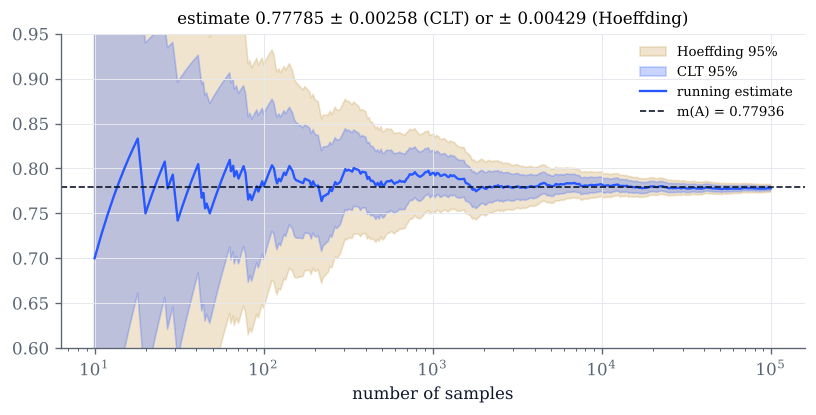

In [6]:
EXACT = 1 - math.log(2) / math.pi
in_A = lambda u: np.sin(1 / u) > 0


def mc_demo(log10_n=5.0, seed=2026):
    n = int(10 ** log10_n)
    rng = np.random.default_rng(seed)
    hits = in_A(rng.random(n)).astype(float)
    N = np.arange(1, n + 1)
    p = np.cumsum(hits) / N
    clt = 1.96 * np.sqrt(np.maximum(p * (1 - p), 1e-12) / N)
    hoeff = np.sqrt(np.log(40) / (2 * N))
    k = np.unique(np.geomspace(10, n, 400).astype(int)) - 1
    fig, ax = plt.subplots(figsize=(8, 3.4))
    ax.fill_between(N[k], p[k] - hoeff[k], p[k] + hoeff[k], color=GOLD, alpha=0.2, label="Hoeffding 95%")
    ax.fill_between(N[k], p[k] - clt[k], p[k] + clt[k], color=COBALT, alpha=0.25, label="CLT 95%")
    ax.plot(N[k], p[k], color=COBALT, lw=1.4, label="running estimate")
    ax.axhline(EXACT, color=INK, ls="--", lw=1, label=f"m(A) = {EXACT:.5f}")
    ax.set(xscale="log", ylim=(0.6, 0.95), xlabel="number of samples",
           title=f"estimate {p[-1]:.5f} ± {clt[-1]:.5f} (CLT) or ± {hoeff[-1]:.5f} (Hoeffding)")
    ax.legend(fontsize=8, loc="upper right")
    plt.show()

mc_demo()

In [7]:
interact(mc_demo,
         log10_n=FloatSlider(value=5.0, min=2.0, max=6.5, step=0.25, continuous_update=False, description="log10 N"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## 4. $\sigma(f)$ on a finite set

On the faces $X=\{1,\dots,6\}$ of a die, $\sigma(f)=\{f^{-1}(B)\}$ (Proposition 3.16) is the set of unions of the
level sets of $f$, so it has $2^{|f(X)|}$ elements. A function $g$ is $\sigma(f)$-measurable exactly when every
preimage $g^{-1}(B)$ is such a union, that is, when $g$ is constant on each level set of $f$: then $g=\varphi\circ f$.

In [8]:
face = np.arange(1, 7)
DIE = {
    "parity 1_(x even)": (face % 2 == 0).astype(int),
    "|x - 3.5|": np.abs(face - 3.5),
    "ceil(x / 2)": np.ceil(face / 2),
    "1_(x >= 5)": (face >= 5).astype(int),
    "x mod 3": face % 3,
    "identity": face,
}


def sigma_demo(f="ceil(x / 2)"):
    F = DIE[f]
    s = sigma_of_function(F)
    levels = [sorted(int(i) + 1 for i in preimage(F, {v})) for v in np.unique(F)]
    print(f"atoms of sigma(f): {levels}")
    print(f"sigma(f) has {len(s)} = 2^{len(levels)} elements")
    for name, G in DIE.items():
        ok = is_measurable(G, s, power_set(np.unique(G).tolist()))
        print(f"  {name:20s} is {'' if ok else 'NOT '}sigma(f)-measurable")

sigma_demo()

atoms of sigma(f): [[1, 2], [3, 4], [5, 6]]
sigma(f) has 8 = 2^3 elements
  parity 1_(x even)    is NOT sigma(f)-measurable
  |x - 3.5|            is NOT sigma(f)-measurable
  ceil(x / 2)          is sigma(f)-measurable
  1_(x >= 5)           is sigma(f)-measurable
  x mod 3              is NOT sigma(f)-measurable
  identity             is NOT sigma(f)-measurable


In [9]:
interact(sigma_demo, f=Dropdown(options=list(DIE), value="ceil(x / 2)", description="f"));

## Things to try

- In section 1, take $f(x)=-\log x$. Why does the largest error stay large however big $n$ is, and which points carry it?
- In section 1, the last function has a jump at $1/2$. Does the jump slow down the convergence of $f_n$? Why not?
- In section 2, find $r$ such that the fat Cantor set has measure $0.9$, and check it with the formula $(1-3r)/(1-2r)$.
- In section 3, count how often, over 20 seeds, the blue band at $N=10^4$ misses $m(A)$. And the gold band?
- In section 4, which function makes every other one measurable? Which makes none of the others measurable?